# Day 4 · Clusters — 306 หกเหลี่ยมฟ้ามืด จับกลุ่มเป็น 24 hotspot

**#30DayMapChallenge 2026 · วันที่ 4 พ.ย. · ธีม Clusters**

ต่อจาก Day 3 (ตัดไทยเป็นหกเหลี่ยม H3 1,738 บล็อก พร้อมค่า `km_nearest`) — วันนี้ถามว่า
**"พื้นที่ฟ้ามืดของไทยจับกลุ่มกันตรงไหนบ้าง หรือกระจายเท่า ๆ กันทั้งประเทศ?"**

วิธี: เลือก hex ที่ **มืดจัด** (`km_nearest < 25 กม.`) แล้วรัน **DBSCAN บนจุดศูนย์กลางของ hex**
จากนั้นทาสี hex *ทั้งก้อน* ตาม label ที่ได้ (ไม่ใช่แค่จุด)

> **รันตามได้เลย: กด Runtime → Run all** — โน้ตบุ๊กนี้อ่านผลลัพธ์ของ Day 3 จาก GitHub
> (`day03_hex_polygons.geojson`) ไม่ต้องคำนวณหกเหลี่ยมใหม่ ถ้าโหลดไม่ได้จะมีปุ่มให้อัปโหลดไฟล์เอง


In [2]:
# ติดตั้ง library ที่ Colab อาจไม่มีมาให้ (numpy/pandas/matplotlib มีอยู่แล้ว)
!pip install -q h3 scikit-learn
import h3
from sklearn.cluster import DBSCAN
import sklearn
print("h3", h3.__version__, "| scikit-learn", sklearn.__version__)

h3 4.5.0 | scikit-learn 1.6.1


## 0. เตรียมฟอนต์ไทย

ใช้ **Noto Sans Thai** ตัวเดียวกับ Day 1–3 (ทดสอบแล้วว่าวาดสระ/วรรณยุกต์ซ้อนเช่น "ท้องฟ้า" ถูกต้อง)

In [3]:
import urllib.request
from fontTools.ttLib import TTFont
from fontTools.varLib.instancer import instantiateVariableFont
from matplotlib import font_manager

urllib.request.urlretrieve(
    "https://github.com/google/fonts/raw/main/ofl/notosansthai/"
    "NotoSansThai%5Bwdth%2Cwght%5D.ttf",
    "NotoSansThai-VF.ttf",
)
for _name, _wght in [("NotoSansThai-Regular", 400), ("NotoSansThai-Bold", 700)]:
    _f = TTFont("NotoSansThai-VF.ttf")
    instantiateVariableFont(_f, {"wght": _wght, "wdth": 100}, inplace=True)
    _f.save(f"{_name}.ttf")
    font_manager.fontManager.addfont(f"{_name}.ttf")

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Noto Sans Thai"
print("ติดตั้งฟอนต์ไทย Noto Sans Thai เรียบร้อย")

ติดตั้งฟอนต์ไทย Noto Sans Thai เรียบร้อย


## 1. โหลดผลลัพธ์ Day 3 (หกเหลี่ยม + ระยะถึงจุดฟ้ามืด)

Day 3 เก็บ `day03_hex_polygons.geojson` ไว้ใน repo — ทุก feature มี geometry ที่ **clip ขอบประเทศแล้ว**
กับ properties `cell` / `km_nearest` / `nearest` / `province` / `area_km2` วันนี้เราไม่ต้องสร้างหกเหลี่ยมใหม่

In [4]:
import json, numpy as np

GEOJSON_URL = ("https://raw.githubusercontent.com/thammarat-ai/geo-notes/main/"
               "posts/day03-polygons/day03_hex_polygons.geojson")
try:
    import urllib.request
    gj = json.load(urllib.request.urlopen(GEOJSON_URL, timeout=60))
    print("โหลด day03_hex_polygons.geojson จาก GitHub ได้")
except Exception:
    from google.colab import files
    up = files.upload()                       # กด Choose Files แล้วเลือกไฟล์ geojson ของ Day 3
    gj = json.loads(next(iter(up.values())).decode("utf-8"))

feats = gj["features"]
cells_id = [f["properties"]["cell"] for f in feats]
km       = np.array([f["properties"]["km_nearest"] for f in feats])
prov     = [f["properties"]["province"] for f in feats]
near     = [f["properties"]["nearest"] for f in feats]
geom     = [f["geometry"] for f in feats]
cen      = np.array([h3.cell_to_latlng(c) for c in cells_id])   # (lat, lon)

def rings_of(g):
    return [g["coordinates"][0]] if g["type"] == "Polygon" else [p[0] for p in g["coordinates"]]
polys = [np.array(r) for g in geom for r in rings_of(g)]

print(f"{len(feats):,} บล็อก | km_nearest: min={km.min():.1f} "
      f"p50={np.median(km):.0f} max={km.max():.0f} กม.")

โหลด day03_hex_polygons.geojson จาก GitHub ได้
1,738 บล็อก | km_nearest: min=0.4 p50=52 max=194 กม.


## 2. ทำไมต้อง "เลือกเซต" ก่อน cluster

นี่คือบทเรียนใหญ่สุดของวันนี้ ถ้าเอา **ทุก hex ทั้งประเทศ** มา DBSCAN จะได้ **blob เดียวกลืนไทยทั้งผืน**
เพราะ hex grid กระจายสม่ำเสมอ → ทุกบล็อกมีเพื่อนบ้านใกล้ ๆ เท่ากันหมด DBSCAN จึงเชื่อมทุกอย่างเข้าด้วยกัน
รันเซลล์นี้เพื่อดูหลักฐาน

In [5]:
R = 6371.0088
lab_all = DBSCAN(eps=25.0/R, min_samples=3, metric="haversine").fit_predict(np.radians(cen))
n_all = len(set(lab_all)) - (1 if -1 in lab_all else 0)
biggest = max((lab_all == c).sum() for c in set(lab_all) if c != -1)
print(f"DBSCAN ทั้ง 1,738 บล็อก → {n_all} กลุ่ม, กลุ่มใหญ่สุด {biggest:,} บล็อก "
      f"({biggest/len(cen)*100:.1f}% ของประเทศ)")
print("=> ไม่ใช่ 'hotspot' แต่คือ 'ทั้งประเทศ' — ต้องจำกัด input ให้เหลือเฉพาะ hex ที่เราสนใจก่อน")

DBSCAN ทั้ง 1,738 บล็อก → 2 กลุ่ม, กลุ่มใหญ่สุด 1,497 บล็อก (86.1% ของประเทศ)
=> ไม่ใช่ 'hotspot' แต่คือ 'ทั้งประเทศ' — ต้องจำกัด input ให้เหลือเฉพาะ hex ที่เราสนใจก่อน


## 3. DBSCAN บน hex "มืดจัด" (km_nearest < 25 กม.)

- **`metric="haversine"`** รับพิกัดเรเดียนแล้ววัดระยะเป็นกม.จริง (ไม่ต้อง project)
- **`eps`**: ระยะระหว่างจุดศูนย์กลาง hex ที่ชิดกัน ≈ **18 กม.** ถ้า `eps < 18` → ไม่มีคู่ไหนเชื่อม (noise หมด)
  ถ้า `eps` ใหญ่เกิน → กลุ่มเล็กเชื่อมเป็นก้อนโต ผมใช้ **25 กม.** = ต่อเฉพาะ hex ที่แตะกันจริง
- **`min_samples=3`** บังคับว่า "กลุ่ม" ต้องมีอย่างน้อย 3 บล็อก ไม่งั้นเป็นแค่คู่โดด

In [6]:
CUT, EPS, MS = 25.0, 25.0, 3
mask = km < CUT
idx  = np.where(mask)[0]
lab  = DBSCAN(eps=EPS/R, min_samples=MS, metric="haversine").fit_predict(np.radians(cen[mask]))
clusters = sorted(c for c in set(lab) if c != -1)
order    = sorted(clusters, key=lambda c: -(lab == c).sum())
rank_of  = {c: i+1 for i, c in enumerate(order)}
sizes    = {c: int((lab == c).sum()) for c in clusters}
noise    = int((lab == -1).sum())

print(f"hex มืดจัด (<{CUT:.0f} กม.) = {int(mask.sum())} บล็อก "
      f"→ {len(clusters)} กลุ่ม + {noise} noise")
print("ขนาดกลุ่ม (มาก→น้อย):", [sizes[c] for c in order[:10]], "...")

hex มืดจัด (<25 กม.) = 306 บล็อก → 24 กลุ่ม + 3 noise
ขนาดกลุ่ม (มาก→น้อย): [50, 47, 28, 23, 21, 13, 12, 11, 11, 8] ...


## 4. (เทียบ) ทำไมไม่ใช้ `h3.compact_cells`

ตอนแรกผมลองยุบ hex ลูก→hex พ่อ (`compact_cells`) ซึ่งฟรีและไม่ต้องตั้งพารามิเตอร์
แต่ **มันยุบก็ต่อเมื่อ hex ลูกครบ 7 ของพ่อตัวนั้น** — กับเซตที่กระจาย ๆ แบบนี้มันแทบไม่ยุบ
รันเซลล์นี้เพื่อเห็นตัวเลข (ผล: ได้ "โซน" เกือบเท่ากับจำนวนบล็อก = โปรยหิมะ ไม่ใช่ก้อน)

In [7]:
best = [cells_id[i] for i in idx]
compacted = sorted(h3.compact_cells(best))
res = [h3.get_resolution(c) for c in compacted]
print(f"compact_cells: {len(best)} บล็อก → {len(compacted)} โซน "
      f"(ยุบจริงแค่ {len(best)-len(compacted)} ครั้ง)")
print("ระดับ resolution ที่ได้:", sorted(set(res)), "(4 = ยุบแล้ว, 5 = ไม่ยุบ)")
print("=> จึงเลือก DBSCAN บน centroid แทน ให้ก้อนที่อ่านออกเป็น hotspot จริง")

compact_cells: 306 บล็อก → 258 โซน (ยุบจริงแค่ 48 ครั้ง)
ระดับ resolution ที่ได้: [4, 5] (4 = ยุบแล้ว, 5 = ไม่ยุบ)
=> จึงเลือก DBSCAN บน centroid แทน ให้ก้อนที่อ่านออกเป็น hotspot จริง


## 5. สรุปตัวเลขต่อ cluster (พื้นที่ / จังหวัด / จุดฟ้ามืดที่ใกล้สุด)

คำนวณ **พื้นที่จริง** ของแต่ละกลุ่มด้วยสูตร spherical polygon area บน geometry ที่ clip แล้ว
(ไม่ใช่ `จำนวนบล็อก × 289` เพราะบล็อกตรงขอบถูกตัด)

In [8]:
import math
from collections import Counter
def ring_area_km2(ring):
    tot = 0.0
    for i in range(len(ring)-1):
        lon1, lat1 = math.radians(ring[i][0]), math.radians(ring[i][1])
        lon2, lat2 = math.radians(ring[i+1][0]), math.radians(ring[i+1][1])
        tot += (lon2-lon1)*(2+math.sin(lat1)+math.sin(lat2))
    return abs(tot*R*R/2.0)
def feat_area(i):
    return sum(ring_area_km2(np.array(r)) for r in rings_of(geom[i]))

stats = []
for c in order:
    sel = idx[lab == c]
    a = sum(feat_area(i) for i in sel)
    cl = cen[sel].mean(0)
    stats.append((rank_of[c], len(sel), a, cl,
                  Counter(prov[i] for i in sel).most_common(1)[0][0],
                  Counter(near[i] for i in sel).most_common(1)[0][0]))
print(f"{'#':>3} {'บล็อก':>5} {'พื้นที่':>10}  จังหวัดหลัก            จุดฟ้ามืดใกล้สุด")
for r, n, a, cl, p, nr in stats[:10]:
    print(f"{r:>3} {n:>5} {a:>8,.0f}กม²  {p:<18} {nr}")
print(f"\nรวมพื้นที่ที่จับกลุ่มได้ = {sum(s[2] for s in stats):,.0f} ตร.กม.")

  # บล็อก    พื้นที่  จังหวัดหลัก            จุดฟ้ามืดใกล้สุด
  1    50   14,895กม²  นครราชสีมา         หาดชมตะวัน อุทยานแห่งชาติทับลาน
  2    47   13,578กม²  เชียงใหม่          ป่าสนวัดจันทร์ อ.อ.ป. กัลยาณิวัฒนา
  3    28    8,296กม²  ชัยภูมิ            เขตรักษาพันธุ์สัตว์ป่าภูเขียว
  4    23    6,607กม²  พิษณุโลก           วนธารา รีสอร์ท
  5    21    6,160กม²  ขอนแก่น            สวนสัตว์ขอนแก่น
  6    13    3,635กม²  ฉะเชิงเทรา         หอดูดาวเฉลิมพระเกียรติฯ ฉะเชิงเทรา
  7    12    3,483กม²  มุกดาหาร           ทุ่งโนนป่าก่อ เขตรักษาพันธุ์สัตว์ป่าภูสีฐาน
  8    11    2,754กม²  พังงา              บ่อแสนวิลล่า
  9    11    3,220กม²  น่าน               อุทยานแห่งชาติศรีน่าน
 10     8    2,369กม²  ลำพูน              อุทยานแห่งชาติแม่ปิง

รวมพื้นที่ที่จับกลุ่มได้ = 87,463 ตร.กม.


## 6. วาดแผนที่ (dark theme ต่อจาก Day 3)

backdrop = hex ทั้ง 1,738 บล็อกสีเทาจาง (ให้รูปทรงไทยยังอยู่) · hex ที่จับกลุ่มได้ทาตามสี cluster
ติดป้ายเฉพาะกลุ่มที่มี ≥ 8 บล็อก เพื่อไม่ให้รก

/tmp/ipykernel_2534/3412971710.py:39: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Noto Sans Thai.
  fig.savefig("day04_clusters_preview.png", dpi=170, facecolor=DARK_BG, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Noto Sans Thai.
  fig.canvas.print_figure(bytes_io, **kw)


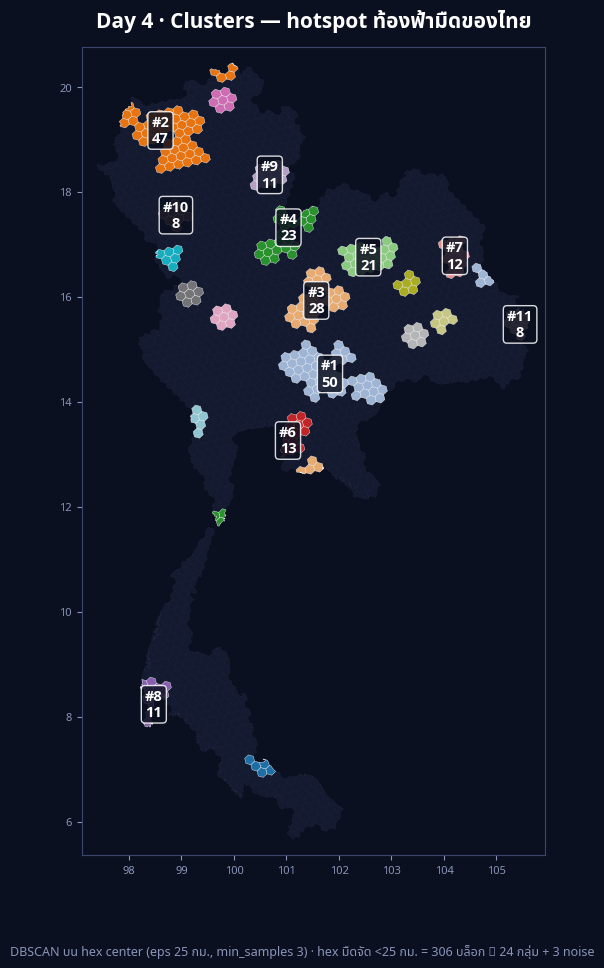

In [9]:
from matplotlib.collections import PolyCollection
DARK_BG, HEX_BG, HEX_EDGE = "#0b1020", "#141a30", "#222842"
cmap = plt.get_cmap("tab20")
LABEL_MIN = 8

fig, ax = plt.subplots(figsize=(9, 10.5), facecolor=DARK_BG)
ax.set_facecolor(DARK_BG)
ax.add_collection(PolyCollection(polys, facecolor=HEX_BG, edgecolor=HEX_EDGE, linewidth=0.2))

zone_of = {}
for i, l in zip(idx, lab):
    if l == -1:
        continue
    col = cmap(rank_of[l] % 20)
    for r in rings_of(geom[i]):
        ax.add_collection(PolyCollection([np.array(r)], facecolor=col,
                                         edgecolor="white", linewidth=0.3, alpha=0.9))
    zone_of.setdefault(l, []).append(np.array(rings_of(geom[i])[0]))

for c in order:
    if sizes[c] < LABEL_MIN:
        continue
    pa = np.vstack(zone_of[c])
    ax.text(pa[:, 0].mean(), pa[:, 1].mean(), f"#{rank_of[c]}\n{sizes[c]}",
            color="white", fontsize=10.5, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc=DARK_BG, ec="white", alpha=0.85), zorder=10)

allc = np.vstack(polys)
ax.set_xlim(allc[:, 0].min()-0.3, allc[:, 0].max()+0.3)
ax.set_ylim(allc[:, 1].min()-0.3, allc[:, 1].max()+0.3)
ax.set_aspect("equal")
for s in ax.spines.values(): s.set_color("#3a466e")
ax.tick_params(colors="#8a94b8", labelsize=8)
ax.set_title("Day 4 · Clusters — hotspot ท้องฟ้ามืดของไทย",
             color="white", fontsize=15, pad=14, fontweight="bold")
fig.text(0.5, 0.015, f"DBSCAN บน hex center (eps {EPS:.0f} กม., min_samples {MS}) · "
         f"hex มืดจัด <{CUT:.0f} กม. = {int(mask.sum())} บล็อก → {len(clusters)} กลุ่ม + {noise} noise",
         color="#8a94b8", fontsize=9, ha="center")
fig.savefig("day04_clusters_preview.png", dpi=170, facecolor=DARK_BG, bbox_inches="tight")
plt.show()

## 7. ส่งออก GeoJSON ผล cluster

ทุก hex ที่จับกลุ่มได้มี properties `cluster` / `rank` / `size` / `km_nearest` / `nearest` / `province`
เปิดใน QGIS หรือเอาไปทำแผนที่ interactive ต่อได้

In [10]:
def geom_of(i):
    return geom[i]
out = []
for i, l in zip(idx, lab):
    if l == -1:
        continue
    out.append({"type": "Feature", "geometry": geom_of(i),
        "properties": {"cell": cells_id[i], "cluster": int(l), "rank": rank_of[l],
                       "size": sizes[l], "km_nearest": float(km[i]),
                       "nearest": near[i], "province": prov[i]}})
gj_out = {"type": "FeatureCollection", "features": out}
with open("day04_clusters.geojson", "w", encoding="utf-8") as f:
    json.dump(gj_out, f, ensure_ascii=False)
import os
print("GeoJSON:", round(os.path.getsize("day04_clusters.geojson")/1024, 1), "KB |", len(out), "features")

GeoJSON: 159.7 KB | 303 features


## 8. แผนที่ interactive (folium · ทางเลือก)

ระบายสี hex ตาม cluster คลิกดูว่าบล็อกนั้นอยู่กลุ่มไหน ใกล้จุดฟ้ามืดใด · พื้นหลัง CARTO dark (ฟรี)

In [12]:
try:
    import folium
    from IPython.display import HTML, display
    import matplotlib.colors as mc

    # 1. ฟังก์ชันสุ่มหรือแปลงสีตาม rank
    def col_for(rank):
        return mc.to_hex(cmap(rank % 20))

    # 2. สร้างออบเจ็กต์แผนที่ด้วย Esri World Dark Gray Canvas
    m = folium.Map(
        location=[13.1, 100.5],
        zoom_start=6,
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ",
        max_zoom=16,
    )

    # 3. วาด GeoJson คลัสเตอร์ลงบนแผนที่
    folium.GeoJson(
        {"type": "FeatureCollection", "features": out},
        style_function=lambda x: {
            "fillColor": col_for(x["properties"]["rank"]),
            "color": "white",
            "weight": 0.3,
            "fillOpacity": 0.8,
        },
        tooltip=folium.GeoJsonTooltip(
            ["rank", "size", "km_nearest", "nearest", "province"], labels=True
        ),
    ).add_to(m)

    m.save("day04_clusters_map.html")
    display(HTML(filename="day04_clusters_map.html"))

except Exception as e:
    print("ข้าม folium:", type(e).__name__, e)

## สรุปสิ่งที่ได้วันนี้

- **เลือกเซต input = นิยาม "cluster" ของคุณ** — DBSCAN ทั้งประเทศให้ blob เดียว ต้องจำกัดเป็น hex มืดจัดก่อน
- **eps ต้องสัมพันธ์กับระยะ grid** — hex res5 ชิดกัน ~18 กม. ตั้ง eps 25 = ต่อเฉพาะบล็อกที่แตะกัน
- **`compact_cells` ไม่ใช่เครื่องมือหา cluster** — มันยุบเฉพาะเมื่อ hex ลูกครบ 7, กับเซตกระจายจึงแทบไม่ยุบ
- **hotspot ใหญ่สุดคือ "ตะวันออก" (นครราชสีมา–สระแก้ว) ไม่ใช่ "เหนือ"** — ต้องรันจริงก่อนสรุป
- **noise ก็เล่าเรื่องได้** — 3 บล็อก "มืดแต่โดด" (เกาะพะลวย, เขาพระวิหาร) คือพื้นที่มืดที่โดนตัดขาด

ไฟล์ที่ได้: `day04_clusters_preview.png` · `day04_clusters.geojson` · `day04_clusters_map.html`